<a href="https://colab.research.google.com/github/manojss14/ML2_MANOJSS_4NI22CI034/blob/main/ML2_exp10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install shap -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = {
    'Math_Score': [
        85, 92, 76, 89, 65,
        95, 72, 88, 60, 91,
        80, 86, 55, 94, 78,
        70, 82, 90, 75, 85
    ],

    'Science_Score': [
        90, 88, 80, 94, 70,
        96, 75, 91, 68, 89,
        82, 85, 60, 97, 76,
        72, 78, 93, 80, 90
    ],

    'Attendance': [
        95, 98, 85, 92, 78,
        99, 80, 90, 75, 96,
        88, 93, 65, 98, 84,
        82, 91, 95, 82, 95
    ]
}

df = pd.DataFrame(data)

# Create target variable
df['Result'] = np.where(
    (df['Math_Score'] + df['Science_Score']) / 2 >= 40,
    1,
    0
)

# Save dataset
df.to_csv('student_performance.csv', index=False)

print("Dataset created successfully!")

display(df.head(20))

Dataset created successfully!


,Math_Score,Science_Score,Attendance,Result
0,85,90,95,1
1,92,88,98,1
2,76,80,85,1
3,89,94,92,1
4,65,70,78,1
5,95,96,99,1
6,72,75,80,1
7,88,91,90,1
8,60,68,75,1
9,91,89,96,1


In [3]:
df = pd.read_csv('student_performance.csv')

print("Dataset loaded successfully!")

print("\nDataset information:")
df.info()

print("\nFirst five records:")
display(df.head())

Dataset loaded successfully!

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Math_Score     20 non-null     int64
 1   Science_Score  20 non-null     int64
 2   Attendance     20 non-null     int64
 3   Result         20 non-null     int64
dtypes: int64(4)
memory usage: 772.0 bytes

First five records:


,Math_Score,Science_Score,Attendance,Result
0,85,90,95,1
1,92,88,98,1
2,76,80,85,1
3,89,94,92,1
4,65,70,78,1


In [4]:
X = df[['Math_Score', 'Science_Score', 'Attendance']]

y = df['Result']

print("Input Features:")
display(X.head())

print("\nTarget Values:")
print(y.head())

Input Features:


,Math_Score,Science_Score,Attendance
0,85,90,95
1,92,88,98
2,76,80,85
3,89,94,92
4,65,70,78



Target Values:
0    1
1    1
2    1
3    1
4    1
Name: Result, dtype: int64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)

print("Testing Data Shape:", X_test.shape)

Training Data Shape: (16, 3)
Testing Data Shape: (4, 3)


In [6]:
model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [7]:
# Make predictions
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=['Fail', 'Pass'],
        zero_division=0
    )
)

Model Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

        Fail       0.00      0.00      0.00         0
        Pass       1.00      1.00      1.00         4

    accuracy                           1.00         4
   macro avg       0.50      0.50      0.50         4
weighted avg       1.00      1.00      1.00         4



In [8]:
# Create SHAP explainer
explainer = shap.TreeExplainer(model)

# Calculate SHAP values for test data
shap_values = explainer.shap_values(X_test)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


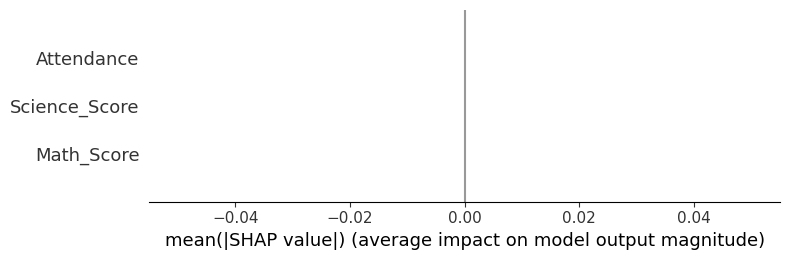

In [9]:
# SHAP summary plot

shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar"
)

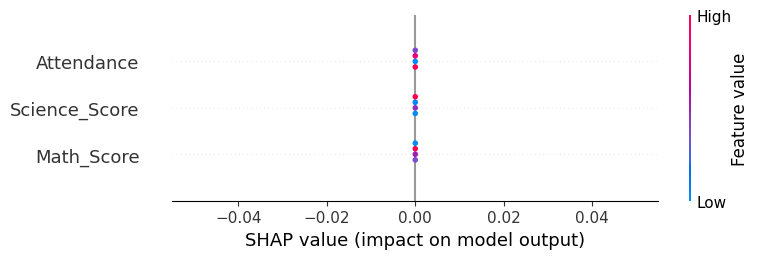

In [10]:
shap.summary_plot(
    shap_values,
    X_test
)

In [11]:
# Select first two test instances
X_two = X_test.iloc[:2]

# Calculate SHAP values
shap_two = explainer.shap_values(X_two)

print("Selected Test Instances:")
display(X_two)

print("\nActual Results:")
print(y_test.loc[X_two.index].values)

print("\nPredicted Results:")
print(model.predict(X_two))

Selected Test Instances:


,Math_Score,Science_Score,Attendance
7,88,91,90
6,72,75,80



Actual Results:
[1 1]

Predicted Results:
[1 1]



Explanation for Test Instance 1


,Feature,Feature_Value,SHAP_Value,Absolute_Importance
0,Math_Score,88,0.0,0.0
1,Science_Score,91,0.0,0.0
2,Attendance,90,0.0,0.0


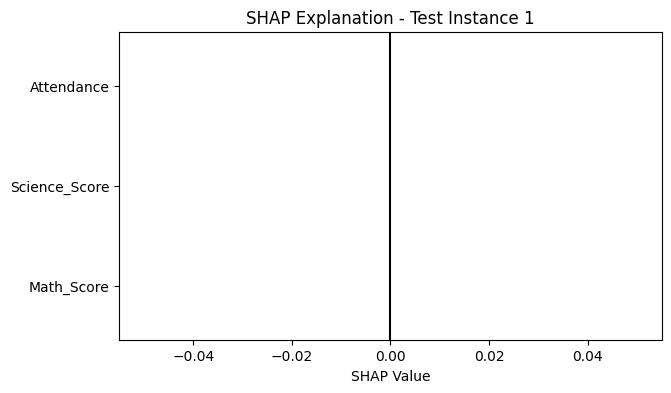


Explanation for Test Instance 2


,Feature,Feature_Value,SHAP_Value,Absolute_Importance
0,Math_Score,72,0.0,0.0
1,Science_Score,75,0.0,0.0
2,Attendance,80,0.0,0.0


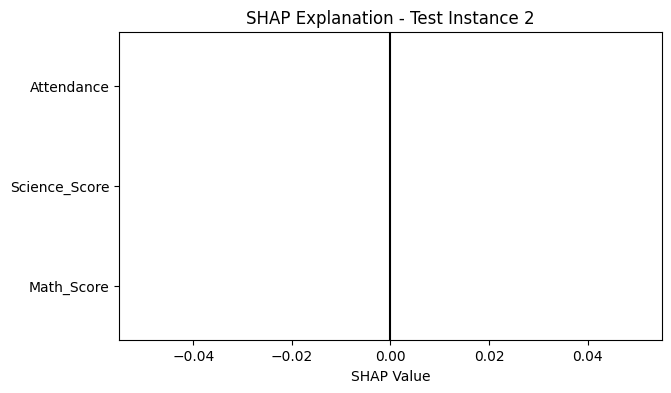

In [12]:
# SHAP explanation for individual instances

for i in range(2):

    print("\nExplanation for Test Instance", i + 1)

    # For binary classification, explain class 1 (Pass)
    values = shap_two

    if isinstance(values, list):
        instance_values = values[1][i]
        base_value = explainer.expected_value[1]
    elif isinstance(values, np.ndarray) and values.ndim == 3:
        instance_values = values[i, :, 1]
        base_value = explainer.expected_value[1]
    else:
        instance_values = values[i]
        base_value = explainer.expected_value

    # Display feature importance
    importance = pd.DataFrame({
        'Feature': X_two.columns,
        'Feature_Value': X_two.iloc[i].values,
        'SHAP_Value': instance_values
    })

    importance['Absolute_Importance'] = (
        importance['SHAP_Value'].abs()
    )

    importance = importance.sort_values(
        by='Absolute_Importance',
        ascending=False
    )

    display(importance)

    # Plot feature contributions
    plt.figure(figsize=(7, 4))

    plt.barh(
        importance['Feature'],
        importance['SHAP_Value'],
        color=[
            'green' if x > 0 else 'red'
            for x in importance['SHAP_Value']
        ]
    )

    plt.axvline(0, color='black')

    plt.title(f"SHAP Explanation - Test Instance {i+1}")
    plt.xlabel("SHAP Value")

    plt.show()

In [15]:
for i in range(2):

    instance = X_test.iloc[[i]]

    prediction = model.predict(instance)[0]

    probability = model.predict_proba(instance)[0]

    print("\n================================")
    print("TEST INSTANCE", i + 1)
    print("===============================")

    print("Feature Values:")
    display(instance)

    print("Actual Result:", y_test.iloc[i])

    print(
        "Predicted Result:",
        "Pass" if prediction == 1 else "Fail"
    )

    # Dynamically check if the model was trained on 1 class or 2
    if len(probability) == 1:
        # Only one class exists in the model training data
        only_class = model.classes_[0]
        prob_fail = 1.0 if only_class == 0 else 0.0
        prob_pass = 1.0 if only_class == 1 else 0.0
    else:
        prob_fail = probability[0]
        prob_pass = probability[1]

    print("Probability of Fail:", round(prob_fail, 4))
    print("Probability of Pass:", round(prob_pass, 4))

    # Get corresponding SHAP values for Pass class
    if isinstance(shap_values, list):
        # For older shap/scikit-learn combinations returning lists of lists
        instance_shap = shap_values[1][i] if len(shap_values) > 1 else shap_values[0][i]
    elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
        # For multi-class tree models (output shape: [instances, features, classes])
        instance_shap = shap_values[i, :, 1] if shap_values.shape[2] > 1 else shap_values[i, :, 0]
    else:
        instance_shap = shap_values[i]

    result = pd.DataFrame({
        'Feature': X_test.columns,
        'SHAP_Importance': instance_shap
    })

    result['Absolute_Importance'] = (
        result['SHAP_Importance'].abs()
    )

    result = result.sort_values(
        by='Absolute_Importance',
        ascending=False
    )

    print("\nFeature Importance:")
    display(result)


TEST INSTANCE 1
Feature Values:


,Math_Score,Science_Score,Attendance
7,88,91,90


Actual Result: 1
Predicted Result: Pass
Probability of Fail: 0.0
Probability of Pass: 1.0

Feature Importance:


,Feature,SHAP_Importance,Absolute_Importance
0,Math_Score,0.0,0.0
1,Science_Score,0.0,0.0
2,Attendance,0.0,0.0



TEST INSTANCE 2
Feature Values:


,Math_Score,Science_Score,Attendance
6,72,75,80


Actual Result: 1
Predicted Result: Pass
Probability of Fail: 0.0
Probability of Pass: 1.0

Feature Importance:


,Feature,SHAP_Importance,Absolute_Importance
0,Math_Score,0.0,0.0
1,Science_Score,0.0,0.0
2,Attendance,0.0,0.0
